# Lista 2: Inteligência Artificial (UFAL)
## Questão 7: Sistema de Apoio ao Diagnóstico Médico Baseado em Casos (CBR)

**Dupla:** Bruno Gomes de Barros Filho (21111360); Antônio Rodrigo Lima de Andrade Tenório (23210707)  

**Disciplina:** ECOM031: Inteligência Artificial  
**Professor:** Evandro de Barros Costa  
**Período:** 2026.2

---

### Enunciado (Q7)

> Desenvolva um Sistema de Apoio ao Diagnóstico Médico Baseado em Casos. O sistema deverá ser capaz de receber como entrada um conjunto de sintomas informados pelo paciente e compará-los com uma base de casos previamente armazenados. Cada caso deverá conter, no mínimo, informações sobre sintomas observados, diagnóstico realizado e tratamento recomendado. O sistema deverá implementar as etapas fundamentais do ciclo de Raciocínio Baseado em Casos:
>
> - Recuperação (Retrieve): localizar os casos mais semelhantes ao problema apresentado;
> - Reutilização (Reuse): utilizar os casos recuperados para propor um possível diagnóstico;
> - Revisão (Revise): permitir a validação ou correção do diagnóstico sugerido;
> - Retenção (Retain): armazenar novos casos ou atualizações na base de conhecimento para uso futuro.
>
> Requisitos mínimos: construir uma base contendo pelo menos 15 casos médicos fictícios; considerar, no mínimo, cinco tipos diferentes de doenças; implementar um mecanismo de cálculo de similaridade entre casos; exibir os casos mais semelhantes encontrados; apresentar o diagnóstico sugerido e um possível tratamento associado; permitir a inclusão de novos casos na base de conhecimento.

A lógica do sistema está nos módulos `cbr_casos.py` (representação e persistência), `cbr_similaridade.py` (métricas), `cbr_ciclo.py` (as quatro etapas) e `cbr_avaliacao.py` (leave-one-out). Este notebook importa esses módulos e mostra o funcionamento passo a passo. A interface interativa fica em `cbr_cli.py`.

**Aviso:** casos, sintomas e tratamentos são fictícios e servem apenas para fins didáticos.

## 0. Configuração

In [1]:
import hashlib
import itertools
import shutil
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix

from cbr_avaliacao import avaliar_loo
from cbr_casos import SINTOMAS, Problema, carregar_base
from cbr_ciclo import LIMIAR_DUPLICATA, SistemaCBR, revisar, revisar_interativo
from cbr_similaridade import (METRICAS_SINTOMAS, PESOS_ATRIBUTOS, PESOS_SINTOMAS,
                              similaridade, similaridades_locais)

from dataclasses import replace

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 10, "font.family": "DejaVu Sans",
})
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # ordem categórica fixa
AZUIS = LinearSegmentedColormap.from_list("azuis", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#104281"])
NOMES_METRICAS = {"simples": "Jaccard simples", "intensidade": "Jaccard com intensidade",
                  "ponderada": "Jaccard ponderado"}

FIGURAS = Path("figures")
FIGURAS.mkdir(exist_ok=True)

def salvar(fig, nome):
    fig.savefig(FIGURAS / f"{nome}.png", dpi=150, bbox_inches="tight")

# Trabalhamos sobre uma cópia temporária: a base versionada não é alterada.
BASE_ORIGINAL = Path("base_casos.json")
hash_original = hashlib.sha256(BASE_ORIGINAL.read_bytes()).hexdigest()
BASE_TRABALHO = Path(tempfile.mkdtemp()) / "base_casos.json"
shutil.copy(BASE_ORIGINAL, BASE_TRABALHO)
casos = carregar_base(BASE_ORIGINAL)
print(f"{len(casos)} casos carregados; cópia de trabalho em {BASE_TRABALHO}")

31 casos carregados; cópia de trabalho em /tmp/tmpabp40xf1/base_casos.json


## 1. A base de casos

A base tem 31 casos fictícios de oito doenças comuns em atendimento ambulatorial no Brasil. Escolhemos de propósito três arboviroses (dengue, chikungunya e zika) e dois quadros respiratórios febris (influenza e COVID-19), porque os sintomas se sobrepõem bastante e isso torna a recuperação menos trivial. Resfriado comum, amigdalite bacteriana e gastroenterite completam a base com quadros mais fáceis de separar.

Alguns casos foram escritos para ficarem perto da fronteira entre doenças: C04 é uma dengue com dor articular e manchas na pele, C08 é uma chikungunya com dor atrás dos olhos, C20 é uma COVID-19 de início súbito parecida com gripe e C28 é uma amigdalite em que as placas ainda não apareceram.

In [2]:
tabela = pd.DataFrame([{
    "caso": c.id, "diagnóstico": c.diagnostico, "idade": c.problema.idade,
    "temp. (°C)": c.problema.temperatura, "dias": c.problema.dias_sintomas,
    "início": c.problema.inicio,
    "sintomas (intensidade)": ", ".join(f"{s}:{v}" for s, v in c.problema.sintomas.items()),
} for c in casos])
tabela

,caso,diagnóstico,idade,temp. (°C),dias,início,sintomas (intensidade)
0,C01,Dengue,27,39.4,3,subito,"dor_retroorbital:3, dor_cabeca:3, mialgia:3, artralgia:1, nauseas:2, cansaco:2"
1,C02,Dengue,45,39.0,4,subito,"dor_retroorbital:2, dor_cabeca:3, mialgia:3, exantema:2, nauseas:1, petequias:1, cansa..."
2,C03,Dengue,12,38.8,2,subito,"dor_retroorbital:2, dor_cabeca:2, mialgia:2, vomito:1, dor_abdominal:1, cansaco:2"
3,C04,Dengue,34,39.2,5,subito,"artralgia:2, mialgia:3, dor_cabeca:2, exantema:2, dor_retroorbital:1, cansaco:2"
4,C05,Chikungunya,52,39.6,4,subito,"artralgia:3, edema_articular:3, mialgia:2, dor_cabeca:2, cansaco:2"
5,C06,Chikungunya,38,39.3,7,subito,"artralgia:3, edema_articular:2, exantema:2, prurido:1, dor_cabeca:1, cansaco:3"
6,C07,Chikungunya,61,38.9,10,subito,"artralgia:3, edema_articular:3, mialgia:1, cansaco:3"
7,C08,Chikungunya,29,39.0,3,subito,"artralgia:2, mialgia:3, dor_cabeca:3, exantema:1, dor_retroorbital:1, nauseas:1"
8,C09,Zika,24,37.6,3,gradual,"exantema:3, prurido:3, conjuntivite:3, artralgia:1, dor_cabeca:1"
9,C10,Zika,31,37.3,4,gradual,"exantema:3, prurido:2, conjuntivite:2, artralgia:2, edema_articular:1"


In [3]:
resumo = tabela.groupby("diagnóstico", sort=False).agg(
    casos=("caso", "count"), temp_media=("temp. (°C)", "mean"),
    dias_medios=("dias", "mean"), idade_min=("idade", "min"), idade_max=("idade", "max"))
resumo.round(1)

,casos,temp_media,dias_medios,idade_min,idade_max
diagnóstico,,,,,
Dengue,4,39.1,3.5,12,45
Chikungunya,4,39.2,6.0,29,61
Zika,4,37.4,3.5,19,31
Influenza,4,38.9,2.5,9,68
COVID-19,4,38.1,4.8,28,63
Resfriado comum,4,37.1,2.5,6,55
Amigdalite bacteriana,4,39.0,2.0,8,25
Gastroenterite,3,37.8,1.7,4,70


O mapa abaixo mostra a intensidade média de cada sintoma por doença (0 quando o sintoma não aparece). Dá para ver o padrão que o sistema precisa reconhecer e onde as doenças se misturam, por exemplo artralgia e exantema nas três arboviroses.

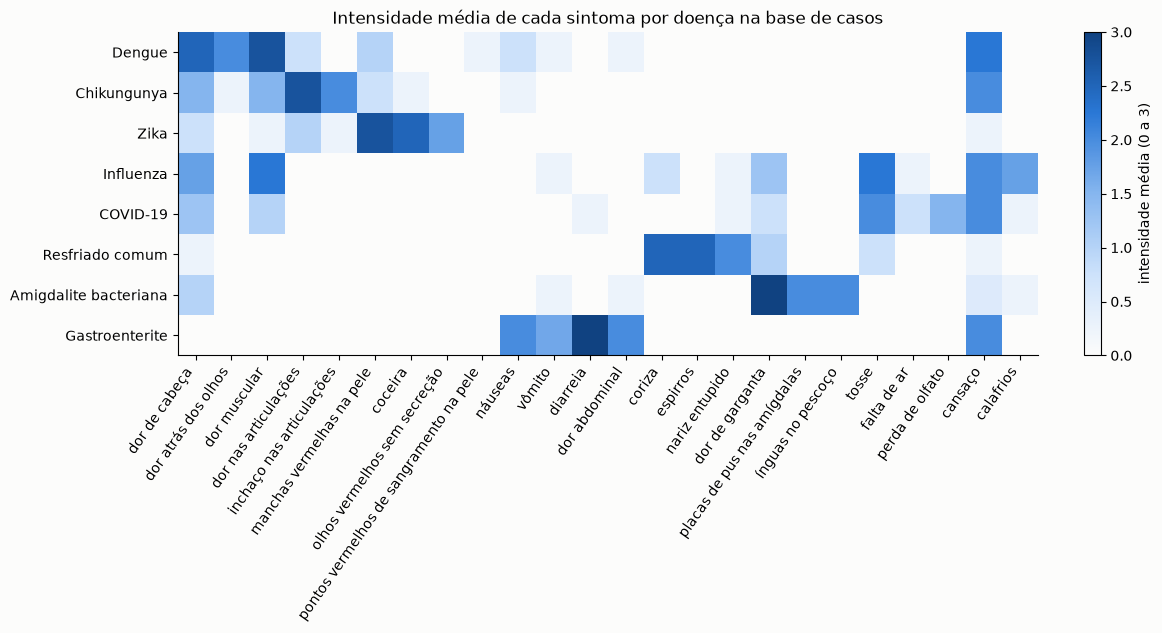

In [4]:
diagnosticos = list(dict.fromkeys(c.diagnostico for c in casos))
intensidade = pd.DataFrame(
    [{**{s: c.problema.sintomas.get(s, 0) for s in SINTOMAS}, "diagnóstico": c.diagnostico} for c in casos]
).groupby("diagnóstico").mean().loc[diagnosticos]

fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(intensidade.values, cmap=AZUIS, vmin=0, vmax=3, aspect="auto")
ax.set_xticks(range(len(SINTOMAS)), [SINTOMAS[s] for s in intensidade.columns], rotation=55, ha="right")
ax.set_yticks(range(len(diagnosticos)), diagnosticos)
ax.set_title("Intensidade média de cada sintoma por doença na base de casos")
fig.colorbar(im, ax=ax, label="intensidade média (0 a 3)", fraction=0.025)
salvar(fig, "q07_perfil_sintomas")
plt.show()

## 2. Representação dos casos

Cada caso é um objeto `Caso` (dataclass) com o problema, a solução e metadados de retenção:

- `problema` (`Problema`, imutável): sintomas como dicionário `nome -> intensidade` (1 leve, 2 moderada, 3 intensa), temperatura em °C, dias desde o início, idade, tipo de início (`subito` ou `gradual`) e alergias a medicamentos;
- `diagnostico` e `tratamento` (lista de orientações);
- `origem` (`base` ou `retido`), `confirmacoes` (quantas vezes uma consulta posterior repetiu o caso) e `observacao`.

O vocabulário de sintomas é fechado (24 nomes), e o construtor de `Problema` rejeita sintomas desconhecidos, intensidades fora de 1 a 3 e valores numéricos implausíveis. A base fica em `base_casos.json`. Abaixo, um caso como objeto Python:

In [5]:
casos[1]

Caso(id='C02', problema=Problema(sintomas={'dor_retroorbital': 2, 'dor_cabeca': 3, 'mialgia': 3, 'exantema': 2, 'nauseas': 1, 'petequias': 1, 'cansaco': 3}, temperatura=39.0, dias_sintomas=4, idade=45, inicio='subito', alergias=('dipirona',)), diagnostico='Dengue', tratamento=['Hidratação oral abundante (cerca de 60 ml/kg/dia)', 'Paracetamol para febre e dor (alergia registrada no prontuário)', 'Evitar AAS e anti-inflamatórios (ibuprofeno, diclofenaco)', 'Retorno imediato se houver sinais de alarme: dor abdominal intensa, sangramento ou vômitos persistentes'], origem='base', confirmacoes=0, observacao='Prova do laço positiva.')

## 3. Similaridade local-global

A similaridade entre dois problemas segue o modelo local-global usado em CBR: cada atributo tem uma similaridade local em [0, 1] e a global é a média ponderada delas.

| atributo | similaridade local | peso |
|---|---|---|
| sintomas | Jaccard ponderado (abaixo) | 0,60 |
| temperatura | $1 - \lvert a-b \rvert / 5$ | 0,15 |
| início | 1 se igual, 0 se diferente | 0,10 |
| dias de sintoma | $1 - \lvert a-b \rvert / 14$ | 0,10 |
| idade | $1 - \lvert a-b \rvert / 100$ | 0,05 |

As diferenças numéricas são truncadas em 0. Para os sintomas comparamos três variantes:

- **Jaccard simples:** $|A \cap B| / |A \cup B|$, só presença ou ausência;
- **Jaccard com intensidade:** $\sum_s \min(a_s, b_s) / \sum_s \max(a_s, b_s)$, com $a_s = 0$ quando o sintoma está ausente;
- **Jaccard ponderado:** a mesma fórmula com um peso $w_s$ por sintoma, $\sum_s w_s \min(a_s, b_s) / \sum_s w_s \max(a_s, b_s)$.

O peso de cada sintoma (1, 2 ou 3) reflete o quanto ele é específico. A tabela confere a escolha contando em quantas doenças da base cada sintoma aparece.

In [6]:
doencas_por_sintoma = {s: {c.diagnostico for c in casos if s in c.problema.sintomas} for s in SINTOMAS}
pesos = pd.DataFrame({
    "peso": PESOS_SINTOMAS,
    "nº de doenças": {s: len(d) for s, d in doencas_por_sintoma.items()},
    "doenças": {s: ", ".join(sorted(d)) for s, d in doencas_por_sintoma.items()},
}).sort_values(["peso", "nº de doenças"], ascending=[False, True])
pesos

,peso,nº de doenças,doenças
petequias,3,1,Dengue
placas_amigdalas,3,1,Amigdalite bacteriana
anosmia,3,1,COVID-19
dor_retroorbital,3,2,"Chikungunya, Dengue"
edema_articular,3,2,"Chikungunya, Zika"
conjuntivite,2,1,Zika
espirros,2,1,Resfriado comum
linfonodos_cervicais,2,1,Amigdalite bacteriana
prurido,2,2,"Chikungunya, Zika"
diarreia,2,2,"COVID-19, Gastroenterite"


In [7]:
print("Correlação de Spearman entre peso e nº de doenças:",
      round(pesos["peso"].corr(pesos["nº de doenças"], method="spearman"), 3))
print("Média de doenças por sintoma, por peso:")
print(pesos.groupby("peso")["nº de doenças"].mean().round(2).to_string())

Correlação de Spearman entre peso e nº de doenças: -0.815
Média de doenças por sintoma, por peso:
peso
1    4.30
2    1.89
3    1.40


Os sintomas de peso 3 aparecem em uma ou duas doenças da base; os de peso 1, em mais de quatro, em média. A correspondência não é exata porque parte dos pesos veio do conhecimento clínico e não só da contagem. Conjuntivite, espirros e ínguas no pescoço aparecem numa única doença da base, mas ficaram com peso 2 porque são comuns em quadros que a base não cobre (outras viroses, rinite alérgica, infecções em geral). Uma base maior mudaria essa contagem, e é por isso que não usamos pesos calculados só a partir dela.

Um exemplo pequeno mostra o efeito do peso. A consulta tem dor atrás dos olhos e dor de cabeça; o caso A compartilha a dor atrás dos olhos e o caso B compartilha a dor de cabeça. No Jaccard simples os dois empatam. No ponderado, A fica bem à frente, porque a dor retro-orbital diz muito mais sobre o diagnóstico.

In [8]:
consulta = {"dor_retroorbital": 2, "dor_cabeca": 2}
caso_a = {"dor_retroorbital": 2, "tosse": 2}
caso_b = {"dor_cabeca": 2, "tosse": 2}
pd.DataFrame({nome: {"caso A": f(consulta, caso_a), "caso B": f(consulta, caso_b)}
              for nome, f in METRICAS_SINTOMAS.items()}).rename(columns=NOMES_METRICAS).round(3)

,Jaccard simples,Jaccard com intensidade,Jaccard ponderado
caso A,0.333,0.333,0.6
caso B,0.333,0.333,0.2


Em seguida, a matriz de similaridade global entre todos os pares de casos, com o Jaccard simples e com o ponderado. Os casos estão agrupados por doença, então blocos escuros na diagonal indicam que casos da mesma doença são parecidos entre si.

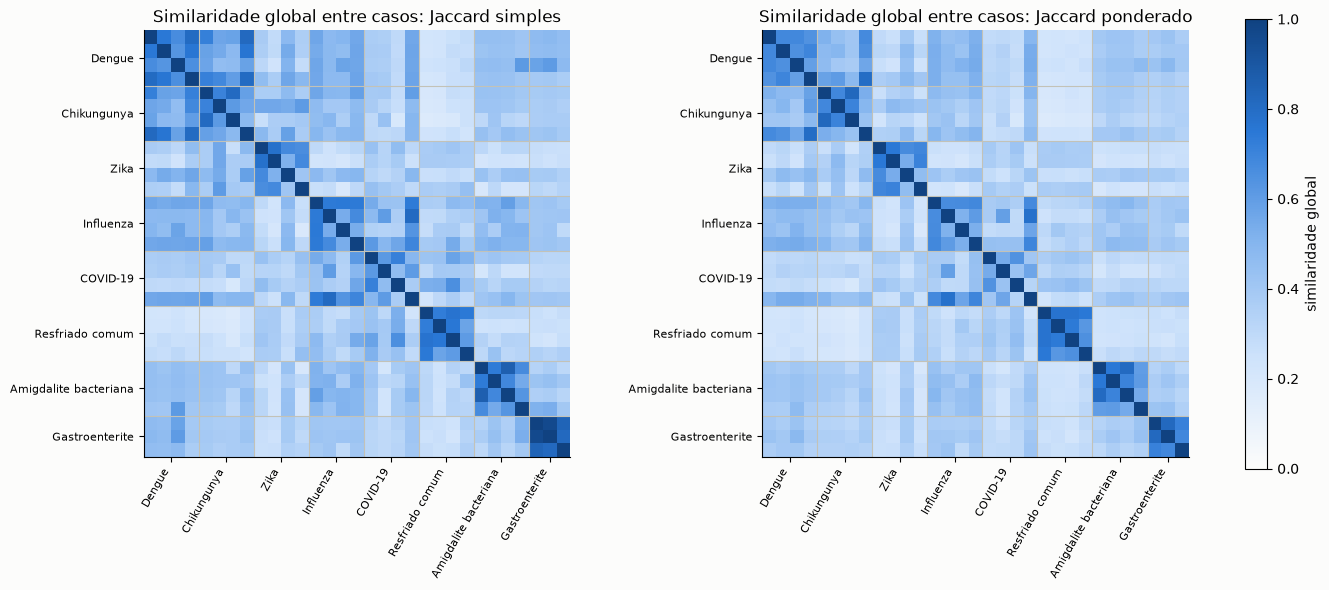

In [9]:
def matriz(sim_sintomas):
    return np.array([[similaridade(a.problema, b.problema, sim_sintomas) for b in casos] for a in casos])

matrizes = {nome: matriz(f) for nome, f in METRICAS_SINTOMAS.items()}
inicio_grupo = [i for i, c in enumerate(casos) if i == 0 or casos[i - 1].diagnostico != c.diagnostico]

fig, eixos = plt.subplots(1, 2, figsize=(14.5, 6), gridspec_kw={"wspace": 0.45})
for ax, nome in zip(eixos, ["simples", "ponderada"]):
    im = ax.imshow(matrizes[nome], cmap=AZUIS, vmin=0, vmax=1)
    for i in inicio_grupo[1:]:
        ax.axhline(i - 0.5, color="#c3c2b7", lw=0.8)
        ax.axvline(i - 0.5, color="#c3c2b7", lw=0.8)
    centros = [(a + b - 1) / 2 for a, b in zip(inicio_grupo, inicio_grupo[1:] + [len(casos)])]
    ax.set_xticks(centros, diagnosticos, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(centros, diagnosticos, fontsize=8)
    ax.set_title(f"Similaridade global entre casos: {NOMES_METRICAS[nome]}")
fig.colorbar(im, ax=eixos, label="similaridade global", fraction=0.02)
salvar(fig, "q07_matriz_similaridade")
plt.show()

In [10]:
mesma = np.array([[a.diagnostico == b.diagnostico for b in casos] for a in casos])
fora_diag = ~np.eye(len(casos), dtype=bool)
linhas = []
for nome, m in matrizes.items():
    intra, inter = m[mesma & fora_diag], m[~mesma]
    vizinho = np.where(fora_diag, m, -1).argmax(axis=1)
    linhas.append({"métrica": NOMES_METRICAS[nome], "média mesma doença": intra.mean(),
                   "média doenças diferentes": inter.mean(), "diferença": intra.mean() - inter.mean(),
                   "maior sim. entre doenças diferentes": inter.max(),
                   "vizinho mais próximo com mesma doença": np.mean(mesma[np.arange(len(casos)), vizinho])})
pd.DataFrame(linhas).set_index("métrica").round(3)

,média mesma doença,média doenças diferentes,diferença,maior sim. entre doenças diferentes,vizinho mais próximo com mesma doença
métrica,,,,,
Jaccard simples,0.664,0.390,0.274,0.816,0.806
Jaccard com intensidade,0.630,0.365,0.264,0.767,0.774
Jaccard ponderado,0.633,0.348,0.286,0.797,0.806


O histograma separa os pares de casos da mesma doença e de doenças diferentes (Jaccard ponderado). A linha tracejada é o limiar de duplicata usado na retenção, discutido na seção 6.

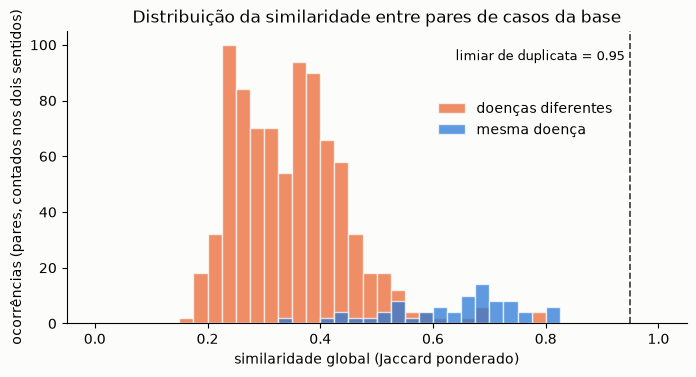

In [11]:
m = matrizes["ponderada"]
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(0, 1, 41)
ax.hist(m[~mesma], bins=bins, color=CORES[1], alpha=0.75, label="doenças diferentes", edgecolor="#fcfcfb", linewidth=1)
ax.hist(m[mesma & fora_diag], bins=bins, color=CORES[0], alpha=0.75, label="mesma doença", edgecolor="#fcfcfb", linewidth=1)
ax.axvline(LIMIAR_DUPLICATA, color="#383835", ls="--", lw=1.2)
ax.text(LIMIAR_DUPLICATA - 0.01, ax.get_ylim()[1] * 0.9, f"limiar de duplicata = {LIMIAR_DUPLICATA}", ha="right", fontsize=9)
ax.set_xlabel("similaridade global (Jaccard ponderado)")
ax.set_ylabel("ocorrências (pares, contados nos dois sentidos)")
ax.set_title("Distribuição da similaridade entre pares de casos da base")
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(0.9, 0.8))
salvar(fig, "q07_distribuicao_similaridade")
plt.show()

## 4. Retrieve e Reuse: exemplos de consultas

O sistema usa k = 3 e o Jaccard ponderado (a seção 7 justifica a escolha). Para cada consulta:

1. **Retrieve:** calcula a similaridade global com todos os casos e devolve os k mais similares;
2. **Reuse:** cada vizinho vota no seu diagnóstico com peso igual à sua similaridade. A confiança é a fração dos votos que foi para o diagnóstico vencedor. O tratamento vem do vizinho mais similar que tem o diagnóstico vencedor e passa por uma adaptação: itens com um medicamento ao qual o paciente é alérgico são trocados por uma alternativa (tabela `SUBSTITUTOS`), e são acrescentadas orientações para criança (menos de 12 anos) ou idoso (60 anos ou mais). Orientações de faixa etária herdadas do caso fonte são descartadas antes, já que o paciente é outro.

In [12]:
sistema = SistemaCBR.de_arquivo(BASE_TRABALHO, k=3)

def mostrar_consulta(problema, sistema=sistema):
    vizinhos = sistema.recuperar(problema)
    sugestao = sistema.reutilizar(problema, vizinhos)
    linhas = []
    for caso, sim in vizinhos:
        locais = similaridades_locais(problema, caso.problema, sistema.sim_sintomas)
        linhas.append({"caso": caso.id, "diagnóstico": caso.diagnostico, "similaridade": round(sim, 3),
                       **{f"local {a}": round(v, 2) for a, v in locais.items()}, "origem": caso.origem})
    print("[Retrieve] casos mais semelhantes:")
    print(pd.DataFrame(linhas).to_string(index=False))
    print(f"\n[Reuse] diagnóstico sugerido: {sugestao.diagnostico} (confiança {sugestao.confianca:.0%})")
    print("votos:", {d: round(v, 3) for d, v in sugestao.votos.items()})
    print(f"tratamento (a partir do caso {sugestao.caso_fonte.id}):")
    for item in sugestao.tratamento:
        print("  -", item)
    for ajuste in sugestao.ajustes:
        print("  * ajuste:", ajuste)
    return sugestao

### Consulta 1: quadro claro de dengue, paciente idosa e alérgica a dipirona

In [13]:
consulta1 = Problema(sintomas={"dor_retroorbital": 3, "dor_cabeca": 3, "mialgia": 2, "nauseas": 1, "cansaco": 2},
                     temperatura=39.1, dias_sintomas=3, idade=72, inicio="subito", alergias=("dipirona",))
sugestao1 = mostrar_consulta(consulta1)

[Retrieve] casos mais semelhantes:
caso diagnóstico  similaridade  local sintomas  local temperatura  local inicio  local dias_sintomas  local idade origem
 C01      Dengue         0.854            0.81               0.94           1.0                 1.00         0.55   base
 C03      Dengue         0.733            0.63               0.94           1.0                 0.93         0.40   base
 C02      Dengue         0.699            0.54               0.98           1.0                 0.93         0.73   base

[Reuse] diagnóstico sugerido: Dengue (confiança 100%)
votos: {'Dengue': 2.286}
tratamento (a partir do caso C01):
  - Hidratação oral abundante (cerca de 60 ml/kg/dia)
  - Não usar dipirona (alergia informada): paracetamol como alternativa, a critério médico
  - Evitar AAS e anti-inflamatórios (ibuprofeno, diclofenaco)
  - Retorno imediato se houver sinais de alarme: dor abdominal intensa, sangramento ou vômitos persistentes
  - Paciente idoso: reavaliar em 24 a 48 h e reforç

A dor atrás dos olhos, de peso 3, puxa os três casos de dengue para o topo. O tratamento do caso C01 teve o item com dipirona trocado e ganhou a orientação para idoso. A proibição de anti-inflamatórios foi mantida.

### Consulta 2: amigdalite em criança alérgica a amoxicilina

In [14]:
consulta2 = Problema(sintomas={"dor_garganta": 3, "placas_amigdalas": 2, "linfonodos_cervicais": 2, "dor_cabeca": 1},
                     temperatura=39.0, dias_sintomas=2, idade=7, inicio="subito", alergias=("amoxicilina",))
sugestao2 = mostrar_consulta(consulta2)

[Retrieve] casos mais semelhantes:
caso           diagnóstico  similaridade  local sintomas  local temperatura  local inicio  local dias_sintomas  local idade origem
 C26 Amigdalite bacteriana         0.872            0.81               0.98           1.0                 0.93         0.90   base
 C25 Amigdalite bacteriana         0.833            0.74               0.94           1.0                 1.00         0.99   base
 C27 Amigdalite bacteriana         0.770            0.63               1.00           1.0                 1.00         0.82   base

[Reuse] diagnóstico sugerido: Amigdalite bacteriana (confiança 100%)
votos: {'Amigdalite bacteriana': 2.475}
tratamento (a partir do caso C26):
  - Não usar amoxicilina (alergia informada): azitromicina como alternativa, a critério médico
  - Ibuprofeno ou paracetamol para dor e febre
  - Gargarejo com água morna e sal
  - Paciente pediátrico: doses calculadas pelo peso
  * ajuste: Item 'Amoxicilina por 10 dias, a critério médico' troca

### Consulta 3: arbovirose ambígua (dor articular, manchas na pele e febre alta)

In [15]:
consulta3 = Problema(sintomas={"artralgia": 2, "exantema": 2, "mialgia": 2, "dor_cabeca": 2, "cansaco": 1},
                     temperatura=38.8, dias_sintomas=4, idade=35, inicio="subito")
sugestao3 = mostrar_consulta(consulta3)

[Retrieve] casos mais semelhantes:
caso diagnóstico  similaridade  local sintomas  local temperatura  local inicio  local dias_sintomas  local idade origem
 C04      Dengue         0.814            0.72               0.92           1.0                 0.93         0.99   base
 C08 Chikungunya         0.700            0.53               0.96           1.0                 0.93         0.94   base
 C06 Chikungunya         0.602            0.40               0.90           1.0                 0.79         0.97   base

[Reuse] diagnóstico sugerido: Chikungunya (confiança 62%)
votos: {'Chikungunya': 1.302, 'Dengue': 0.814}
tratamento (a partir do caso C08):
  - Repouso e hidratação oral
  - Paracetamol ou dipirona para febre e dor articular
  - Compressas frias nas articulações inflamadas
  - Evitar anti-inflamatórios até descartar dengue


Aqui não há nenhum sintoma de peso 3 e os vizinhos se dividem entre doenças, então a confiança cai. Vale comparar o ranking produzido pelas três variantes da similaridade de sintomas:

In [16]:
def ranking(problema, nome, k=5):
    s = SistemaCBR(casos, k=k, sim_sintomas=METRICAS_SINTOMAS[nome])
    return [f"{c.id} {c.diagnostico} ({v:.3f})" for c, v in s.recuperar(problema)]

pd.DataFrame({NOMES_METRICAS[n]: ranking(consulta3, n) for n in METRICAS_SINTOMAS},
             index=[f"{i}º" for i in range(1, 6)])

,Jaccard simples,Jaccard com intensidade,Jaccard ponderado
1º,C04 Dengue (0.880),C04 Dengue (0.830),C04 Dengue (0.814)
2º,C05 Chikungunya (0.767),C08 Chikungunya (0.707),C08 Chikungunya (0.700)
3º,C08 Chikungunya (0.727),C05 Chikungunya (0.667),C06 Chikungunya (0.602)
4º,C01 Dengue (0.714),C02 Dengue (0.636),C02 Dengue (0.589)
5º,C06 Chikungunya (0.705),C06 Chikungunya (0.602),C05 Chikungunya (0.583)


O gráfico decompõe a similaridade global dos cinco casos mais próximos da consulta 3 na contribuição de cada atributo (peso vezes similaridade local).

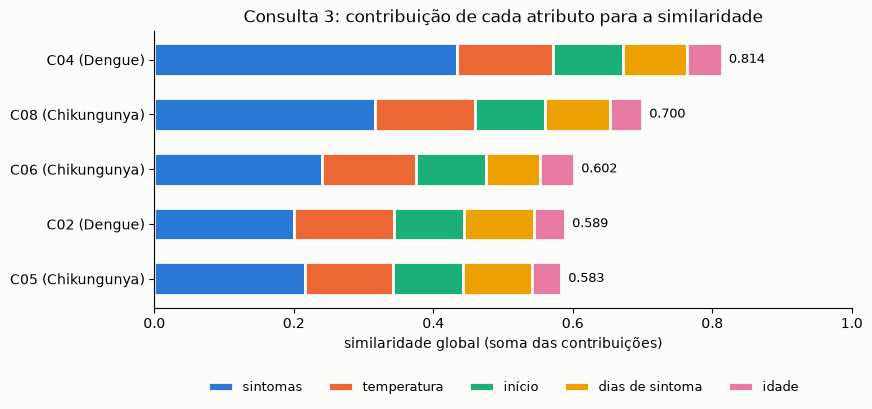

In [17]:
vizinhos3 = sistema.recuperar(consulta3, k=5)
contrib = pd.DataFrame([{a: PESOS_ATRIBUTOS[a] * v for a, v in similaridades_locais(consulta3, c.problema).items()}
                        for c, _ in vizinhos3], index=[f"{c.id} ({c.diagnostico})" for c, _ in vizinhos3])[::-1]
rotulos = {"sintomas": "sintomas", "temperatura": "temperatura", "inicio": "início",
           "dias_sintomas": "dias de sintoma", "idade": "idade"}
fig, ax = plt.subplots(figsize=(9, 3.6))
esquerda = np.zeros(len(contrib))
for cor, atributo in zip(CORES, contrib.columns):
    ax.barh(contrib.index, contrib[atributo], left=esquerda, color=cor, label=rotulos[atributo],
            height=0.6, edgecolor="#fcfcfb", linewidth=2)
    esquerda += contrib[atributo].values
for y, total in enumerate(esquerda):
    ax.text(total + 0.01, y, f"{total:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel("similaridade global (soma das contribuições)")
ax.set_title("Consulta 3: contribuição de cada atributo para a similaridade")
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=9)
salvar(fig, "q07_contribuicoes_consulta3")
plt.show()

### Consulta 4: quadro respiratório entre gripe e COVID-19

In [18]:
consulta4 = Problema(sintomas={"tosse": 2, "cansaco": 2, "mialgia": 2, "dor_cabeca": 1, "dor_garganta": 1},
                     temperatura=38.2, dias_sintomas=4, idade=45, inicio="gradual")
sugestao4 = mostrar_consulta(consulta4)

[Retrieve] casos mais semelhantes:
caso diagnóstico  similaridade  local sintomas  local temperatura  local inicio  local dias_sintomas  local idade origem
 C16   Influenza         0.690            0.67               0.94           0.0                 1.00         0.97   base
 C20    COVID-19         0.609            0.54               0.92           0.0                 1.00         0.95   base
 C17    COVID-19         0.593            0.35               0.94           1.0                 0.93         0.95   base

[Reuse] diagnóstico sugerido: COVID-19 (confiança 64%)
votos: {'COVID-19': 1.202, 'Influenza': 0.69}
tratamento (a partir do caso C20):
  - Isolamento domiciliar enquanto houver sintomas
  - Paracetamol ou dipirona para febre
  - Monitorar saturação de oxigênio e frequência respiratória
  - Procurar atendimento se houver falta de ar ou saturação abaixo de 94%


Sem perda de olfato, o que separa as duas doenças são o início e a temperatura. Se a mesma pessoa relatasse anosmia, o quadro mudaria bastante:

In [19]:
_ = mostrar_consulta(replace(consulta4, sintomas={**consulta4.sintomas, "anosmia": 2}))

[Retrieve] casos mais semelhantes:
caso diagnóstico  similaridade  local sintomas  local temperatura  local inicio  local dias_sintomas  local idade origem
 C17    COVID-19         0.805            0.71               0.94           1.0                 0.93         0.95   base
 C19    COVID-19         0.651            0.47               0.88           1.0                 0.93         0.83   base
 C18    COVID-19         0.634            0.45               0.96           1.0                 0.79         0.82   base

[Reuse] diagnóstico sugerido: COVID-19 (confiança 100%)
votos: {'COVID-19': 2.089}
tratamento (a partir do caso C17):
  - Isolamento domiciliar enquanto houver sintomas
  - Paracetamol ou dipirona para febre
  - Monitorar saturação de oxigênio e frequência respiratória
  - Procurar atendimento se houver falta de ar ou saturação abaixo de 94%


## 5. Revise: validação ou correção pelo médico

A função `revisar` recebe a sugestão e devolve o caso resolvido. Sem argumentos extras, o médico confirma diagnóstico e tratamento; ao passar `diagnostico` e `tratamento`, ele corrige a sugestão. Se o diagnóstico for corrigido sem tratamento novo, a função recusa, porque o tratamento sugerido era para outra doença.

Na CLI a revisão é interativa (`revisar_interativo`). Aqui simulamos as respostas do médico com uma lista, que é o mesmo mecanismo usado nos testes.

In [20]:
respostas = iter(["n", "Chikungunya", "Repouso; Paracetamol para dor; Compressas frias nas articulações",
                  "Sorologia positiva para chikungunya"])

def medico(pergunta):
    resposta = next(respostas)
    print(pergunta + resposta)
    return resposta

caso3 = revisar_interativo(consulta3, sugestao3, perguntar=medico)
caso3

Confirma o diagnóstico 'Chikungunya'? [s/n] n
Diagnóstico correto: Chikungunya
Tratamento (itens separados por ';'): Repouso; Paracetamol para dor; Compressas frias nas articulações
Observação (opcional): Sorologia positiva para chikungunya


Caso(id='', problema=Problema(sintomas={'artralgia': 2, 'exantema': 2, 'mialgia': 2, 'dor_cabeca': 2, 'cansaco': 1}, temperatura=38.8, dias_sintomas=4, idade=35, inicio='subito', alergias=()), diagnostico='Chikungunya', tratamento=['Repouso', 'Paracetamol para dor', 'Compressas frias nas articulações'], origem='novo', confirmacoes=0, observacao='Sorologia positiva para chikungunya')

## 6. Retain: inclusão de casos novos

`SistemaCBR.reter` aplica a política de retenção:

- se já existe um caso **com o mesmo diagnóstico** e similaridade global maior ou igual a `LIMIAR_DUPLICATA` (0,95), o caso novo não entra; o caso existente recebe uma confirmação (`confirmacoes += 1`), que é a forma de "atualização" da base prevista no enunciado;
- caso contrário, o caso entra com um id novo e `origem = "retido"`, e a base é gravada no JSON.

O limiar foi escolhido olhando a seção 3: a maior similaridade entre dois casos distintos da mesma doença na base é bem menor que 0,95, então nenhum caso cadastrado seria tratado como duplicata de outro. Dois atendimentos só ultrapassam 0,95 quando têm praticamente os mesmos sintomas e valores numéricos muito próximos. Pares de doenças diferentes nunca são comparados, porque um caso quase igual com diagnóstico diferente é informação nova (um conflito que interessa guardar).

In [21]:
intra = matrizes["ponderada"][mesma & fora_diag]
print(f"Maior similaridade entre casos distintos da mesma doença: {intra.max():.3f} (limiar = {LIMIAR_DUPLICATA})")

Maior similaridade entre casos distintos da mesma doença: 0.823 (limiar = 0.95)


### Um caso de doença que a base não conhece

Paciente com nariz entupido, dor de cabeça forte e coriza há 12 dias, febre baixa e início gradual. A base não tem sinusite, então o sistema propõe a doença mais parecida que conhece.

In [22]:
sinusite = Problema(sintomas={"congestao_nasal": 3, "dor_cabeca": 3, "coriza": 2},
                    temperatura=38.0, dias_sintomas=12, idade=40, inicio="gradual")
sugestao_s = mostrar_consulta(sinusite)

[Retrieve] casos mais semelhantes:
caso     diagnóstico  similaridade  local sintomas  local temperatura  local inicio  local dias_sintomas  local idade origem
 C23 Resfriado comum         0.599            0.50               0.76           1.0                 0.43         0.85   base
 C21 Resfriado comum         0.515            0.37               0.80           1.0                 0.29         0.90   base
 C22 Resfriado comum         0.501            0.33               0.88           1.0                 0.36         0.66   base

[Reuse] diagnóstico sugerido: Resfriado comum (confiança 100%)
votos: {'Resfriado comum': 1.615}
tratamento (a partir do caso C23):
  - Lavagem nasal com soro fisiológico
  - Hidratação oral
  - Paracetamol se houver desconforto


O médico corrige para sinusite bacteriana e o caso é retido:

In [23]:
TRATAMENTO_SINUSITE = ["Lavagem nasal com soro fisiológico", "Antibiótico por 7 dias, a critério médico",
                       "Analgésico para dor facial"]
caso_s = revisar(sinusite, sugestao_s, diagnostico="Sinusite bacteriana", tratamento=TRATAMENTO_SINUSITE,
                 observacao="Dor facial à palpação")
resultado = sistema.reter(caso_s)
print(resultado)
print("casos na base de trabalho:", len(carregar_base(BASE_TRABALHO)))

ResultadoRetencao(retido=True, id_caso='C32', similaridade=0.0)
casos na base de trabalho: 32


Dias depois chega outro paciente com quadro parecido. O caso retido é recuperado em primeiro lugar, com folga:

In [24]:
paciente2 = Problema(sintomas={"congestao_nasal": 3, "dor_cabeca": 2, "coriza": 2},
                     temperatura=37.9, dias_sintomas=10, idade=45, inicio="gradual")
sugestao_2 = mostrar_consulta(paciente2)

[Retrieve] casos mais semelhantes:
caso         diagnóstico  similaridade  local sintomas  local temperatura  local inicio  local dias_sintomas  local idade origem
 C32 Sinusite bacteriana         0.920            0.90               0.98           1.0                 0.86         0.95 retido
 C23     Resfriado comum         0.639            0.53               0.78           1.0                 0.57         0.90   base
 C21     Resfriado comum         0.542            0.39               0.82           1.0                 0.43         0.85   base

[Reuse] diagnóstico sugerido: Resfriado comum (confiança 56%)
votos: {'Resfriado comum': 1.181, 'Sinusite bacteriana': 0.92}
tratamento (a partir do caso C23):
  - Lavagem nasal com soro fisiológico
  - Hidratação oral
  - Paracetamol se houver desconforto


Mesmo assim o voto ainda escolhe resfriado, com confiança baixa: um único caso de sinusite com similaridade 0,92 perde para dois casos de resfriado que, somados, têm mais peso. É uma limitação do voto ponderado com k = 3 quando uma doença tem só um caso na base. O alerta está na confiança de 56% e na tabela de vizinhos, que mostra o caso de sinusite no topo. O médico corrige de novo e o segundo caso também é retido:

In [25]:
print(sistema.reter(revisar(paciente2, sugestao_2, "Sinusite bacteriana", TRATAMENTO_SINUSITE)))

ResultadoRetencao(retido=True, id_caso='C33', similaridade=0.9202142857142858)


Com dois casos de sinusite na base, um terceiro paciente já recebe a sugestão correta:

In [26]:
paciente3 = Problema(sintomas={"congestao_nasal": 2, "dor_cabeca": 3, "coriza": 2, "tosse": 1},
                     temperatura=38.2, dias_sintomas=9, idade=33, inicio="gradual")
sugestao_3 = mostrar_consulta(paciente3)

[Retrieve] casos mais semelhantes:
caso         diagnóstico  similaridade  local sintomas  local temperatura  local inicio  local dias_sintomas  local idade origem
 C32 Sinusite bacteriana         0.860            0.82               0.96           1.0                 0.79         0.93 retido
 C33 Sinusite bacteriana         0.814            0.73               0.94           1.0                 0.93         0.88 retido
 C23     Resfriado comum         0.611            0.50               0.72           1.0                 0.64         0.78   base

[Reuse] diagnóstico sugerido: Sinusite bacteriana (confiança 73%)
votos: {'Sinusite bacteriana': 1.674, 'Resfriado comum': 0.611}
tratamento (a partir do caso C32):
  - Lavagem nasal com soro fisiológico
  - Antibiótico por 7 dias, a critério médico
  - Analgésico para dor facial


Por último, o primeiro paciente volta a ser registrado com o mesmo quadro (temperatura 0,1 °C diferente) e o mesmo diagnóstico. A similaridade com o caso retido passa do limiar, então a base não ganha um caso repetido; o caso existente recebe uma confirmação:

In [27]:
repetido = replace(sinusite, temperatura=38.1)
print(sistema.reter(revisar(repetido, sistema.consultar(repetido), "Sinusite bacteriana", TRATAMENTO_SINUSITE)))
base_final = carregar_base(BASE_TRABALHO)
print(f"{resultado.id_caso}: confirmacoes = {next(c for c in base_final if c.id == resultado.id_caso).confirmacoes}")
print("casos na base de trabalho:", len(base_final))

ResultadoRetencao(retido=False, id_caso='C32', similaridade=0.997)
C32: confirmacoes = 1
casos na base de trabalho: 33


Por fim, a base versionada continua igual ao início do notebook:

In [28]:
assert hashlib.sha256(BASE_ORIGINAL.read_bytes()).hexdigest() == hash_original
print("base_casos.json inalterado")

base_casos.json inalterado


## 7. Avaliação leave-one-out

Para estimar a qualidade da recuperação, cada caso da base original foi retirado e consultado contra os 30 restantes. Medimos:

- **acurácia top-1:** o diagnóstico votado é o diagnóstico real;
- **acurácia top-3:** o diagnóstico real está entre os três diagnósticos distintos mais próximos no ranking completo (uma lista de diagnósticos diferenciais).

Variamos k e a similaridade dos sintomas.

In [29]:
resultados = []
for nome, f in METRICAS_SINTOMAS.items():
    for k in (1, 3, 5, 7):
        df = avaliar_loo(casos, k=k, sim_sintomas=f)
        resultados.append({"métrica": NOMES_METRICAS[nome], "k": k, "acertos top-1": int(df["acerto_top1"].sum()),
                           "top-1": df["acerto_top1"].mean(), "top-3": df["acerto_top3"].mean()})
resultados = pd.DataFrame(resultados)
resultados.pivot(index="k", columns="métrica", values="top-1")[list(NOMES_METRICAS.values())].round(3)

métrica,Jaccard simples,Jaccard com intensidade,Jaccard ponderado
k,,,
1,0.806,0.774,0.806
3,0.903,0.903,0.935
5,0.839,0.871,0.935
7,0.806,0.839,0.871


Acurácia top-3: mínimo 1.000 e máximo 1.000 entre as 12 combinações


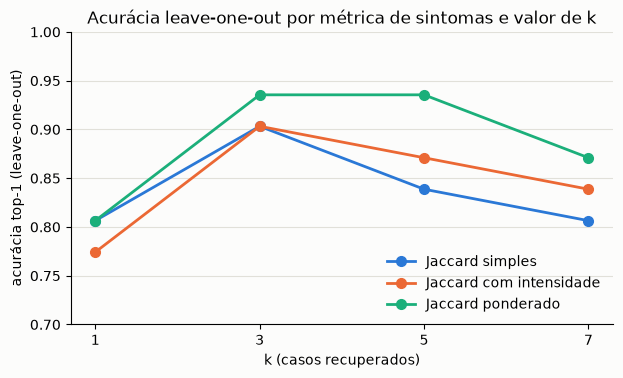

In [30]:
print(f"Acurácia top-3: mínimo {resultados['top-3'].min():.3f} e máximo {resultados['top-3'].max():.3f} entre as 12 combinações")
fig, ax = plt.subplots(figsize=(7, 3.8))
for cor, nome in zip(CORES, NOMES_METRICAS.values()):
    r = resultados[resultados["métrica"] == nome]
    ax.plot(r["k"], r["top-1"], marker="o", markersize=7, lw=2, color=cor, label=nome)
ax.set_xticks([1, 3, 5, 7])
ax.set_ylim(0.7, 1.0)
ax.set_xlabel("k (casos recuperados)")
ax.set_ylabel("acurácia top-1 (leave-one-out)")
ax.set_title("Acurácia leave-one-out por métrica de sintomas e valor de k")
ax.grid(axis="y", color="#e1e0d9", lw=0.8)
ax.legend(frameon=False)
salvar(fig, "q07_loo_metricas")
plt.show()

A configuração adotada (Jaccard ponderado, k = 3) foi a melhor junto com k = 5; ficamos com k = 3 por ser a menor. A matriz de confusão dessa configuração:

top-1 = 0.935 (29/31), top-3 = 1.000, confiança média = 0.825


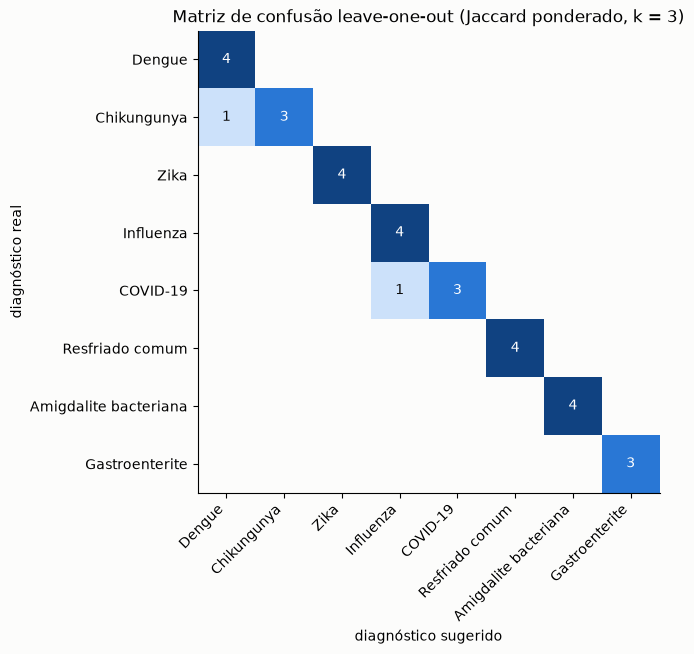

In [31]:
loo = avaliar_loo(casos, k=3)
print(f"top-1 = {loo['acerto_top1'].mean():.3f} ({loo['acerto_top1'].sum()}/{len(loo)}), "
      f"top-3 = {loo['acerto_top3'].mean():.3f}, confiança média = {loo['confianca'].mean():.3f}")
cm = confusion_matrix(loo["real"], loo["previsto"], labels=diagnosticos)
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap=AZUIS, vmin=0, vmax=cm.max())
for i, j in itertools.product(range(len(diagnosticos)), repeat=2):
    if cm[i, j]:
        ax.text(j, i, cm[i, j], ha="center", va="center", color="#ffffff" if cm[i, j] > 2 else "#0b0b0b")
ax.set_xticks(range(len(diagnosticos)), diagnosticos, rotation=45, ha="right")
ax.set_yticks(range(len(diagnosticos)), diagnosticos)
ax.set_xlabel("diagnóstico sugerido")
ax.set_ylabel("diagnóstico real")
ax.set_title("Matriz de confusão leave-one-out (Jaccard ponderado, k = 3)")
salvar(fig, "q07_matriz_confusao")
plt.show()

### Análise dos erros

In [32]:
erros = loo[~loo["acerto_top1"]]
for _, linha in erros.iterrows():
    caso = next(c for c in casos if c.id == linha["caso"])
    resto = SistemaCBR([c for c in casos if c.id != caso.id], k=3)
    print(f"{caso.id} real = {caso.diagnostico}, sugerido = {linha['previsto']} (confiança {linha['confianca']:.0%})")
    print("   sintomas:", caso.problema.sintomas, "| início:", caso.problema.inicio)
    print("   vizinhos:", [f"{c.id} {c.diagnostico} {s:.3f}" for c, s in resto.recuperar(caso.problema)])

C08 real = Chikungunya, sugerido = Dengue (confiança 100%)
   sintomas: {'artralgia': 2, 'mialgia': 3, 'dor_cabeca': 3, 'exantema': 1, 'dor_retroorbital': 1, 'nauseas': 1} | início: subito
   vizinhos: ['C04 Dengue 0.797', 'C01 Dengue 0.675', 'C02 Dengue 0.652']
C20 real = COVID-19, sugerido = Influenza (confiança 100%)
   sintomas: {'tosse': 2, 'mialgia': 2, 'cansaco': 3, 'dor_cabeca': 2, 'calafrios': 1, 'falta_ar': 1} | início: subito
   vizinhos: ['C14 Influenza 0.781', 'C16 Influenza 0.693', 'C13 Influenza 0.679']


In [33]:
print("Casos com confiança abaixo de 100% no leave-one-out:")
loo[loo["confianca"] < 1].round(3)

Casos com confiança abaixo de 100% no leave-one-out:


,caso,real,previsto,confianca,sim_max,acerto_top1,acerto_top3
0,C01,Dengue,Dengue,0.669,0.682,True,True
1,C02,Dengue,Dengue,0.678,0.692,True,True
3,C04,Dengue,Dengue,0.626,0.797,True,True
4,C05,Chikungunya,Chikungunya,0.722,0.823,True,True
5,C06,Chikungunya,Chikungunya,0.695,0.701,True,True
6,C07,Chikungunya,Chikungunya,0.760,0.823,True,True
10,C11,Zika,Zika,0.713,0.670,True,True
12,C13,Influenza,Influenza,0.665,0.680,True,True
13,C14,Influenza,Influenza,0.620,0.781,True,True
14,C15,Influenza,Influenza,0.678,0.671,True,True


In [34]:
arbo = ["Dengue", "Chikungunya", "Zika"]
sub = loo[loo["real"].isin(arbo)]
print(f"Arboviroses: {sub['acerto_top1'].sum()}/{len(sub)} acertos top-1")
pd.crosstab(sub["real"], sub["previsto"])

Arboviroses: 11/12 acertos top-1


previsto,Chikungunya,Dengue,Zika
real,,,
Chikungunya,3,1,0
Dengue,0,4,0
Zika,0,0,4


Comparação por caso entre o Jaccard simples e o ponderado (k = 3), para ver quais casos mudam de resultado:

In [35]:
loo_simples = avaliar_loo(casos, k=3, sim_sintomas=METRICAS_SINTOMAS["simples"])
dif = loo_simples[["caso", "real", "previsto"]].merge(loo[["caso", "previsto"]], on="caso",
                                                      suffixes=(" (simples)", " (ponderado)"))
dif[dif["previsto (simples)"] != dif["previsto (ponderado)"]]

,caso,real,previsto (simples),previsto (ponderado)
4,C05,Chikungunya,Dengue,Chikungunya


## 8. Conclusões

O sistema implementa as quatro etapas do ciclo CBR sobre uma base de 31 casos fictícios de oito doenças. Na avaliação leave-one-out, a configuração escolhida (Jaccard ponderado, k = 3) acertou 29 dos 31 casos em top-1, e o diagnóstico real sempre apareceu entre os três diagnósticos mais próximos. Os dois erros (C08 e C20) são justamente casos escritos para ficar na fronteira entre doenças. Nos dois, os três vizinhos eram da doença errada e a confiança saiu 100%, ou seja, a confiança do voto sozinha não detecta esse tipo de erro, e a revisão médica continua necessária.

Em relação ao Jaccard simples, o ponderado corrigiu um caso (C05, chikungunya com edema articular, sintoma de peso 3) e não piorou nenhum. Com 31 casos cada acerto vale cerca de 3 pontos percentuais, então essa diferença é pequena e precisa ser lida com cautela. Nos quadros sem sinal específico, como a consulta 3, as métricas discordam no ranking e a confiança cai.

A retenção mostrou como a base aprende com o uso: a sinusite, ausente da base original, passou a ser sugerida a partir do segundo caso retido, sem nenhuma mudança no código, e um atendimento repetido virou confirmação em vez de duplicata.